# Лабораторная работа №4
## Исследование случайного леса

**Цель:** повторить пункты 2–4 первой работы: бейзлайны Random Forest из sklearn для классификации и регрессии, проверка улучшений на CV, собственная реализация леса на основе CART, перенос выбранных улучшений и сравнение результатов.

Данные и условия совпадают с [первой](research-1.ipynb), [второй](research-2.ipynb) и [третьей](research-3.ipynb) работами:
- [Steam Game Hits](https://www.kaggle.com/datasets/vedauv/what-makes-a-steam-game-a-hit-8000-games): цель `hit`; основная метрика **Average Precision (AP)**, дополнительные — F1, precision, recall, balanced accuracy, ROC AUC, accuracy. Порог вероятности >0.5, при равенстве выбираем класс 0. AP оценивает ранжирование редкого класса без привязки к одному порогу.
- [Video Games Sales](https://www.kaggle.com/datasets/ulrikthygepedersen/video-games-sales): цель `global_sales` в **миллионах копий**; основная метрика **MAE**, дополнительные — RMSE и R². MAE интерпретируется как абсолютная ошибка, RMSE сильнее выделяет крупные промахи.

Steam-набор **синтетический**: `hit=1` означает верхние 20% по выручке. Выводы относятся к генератору. В признаках нет выручки, числа владельцев, отзывов и других результатов после релиза. Wishlist — дорелизный по описанию автора; доступность остальных характеристик до релиза предполагается в учебном сценарии. В продажах исключены ранг и региональные продажи, почти раскрывающие ответ; название используется только для группировки. Продажи накоплены к моменту сбора и не имеют общего горизонта наблюдения.

Разбиения прежние: seed=42, 80/20, стратификация Steam, группировка продаж по названию, 3-fold CV внутри train. Преобразователи обучаются внутри Pipeline на train-fold; тест не участвует в выборе решений. Ноутбук самодостаточен: запускать из корня проекта, другие работы заранее выполнять не требуется. Все пояснения находятся в Markdown; комментариев через `#` в коде нет. В `results/research-4/` сохраняются только итоговые таблицы CV и тестовых метрик.

### Импорт и воспроизводимость
Используем существующие зависимости и фиксированный seed. Леса и подбор параметров работают последовательно (`n_jobs=1`), без дочерних процессов; число потоков численных библиотек ограничено двумя.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
from pathlib import Path
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedKFold, GroupKFold, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from threadpoolctl import threadpool_limits
SEED = 42
np.random.seed(SEED)
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
assert (ROOT / "data").exists(), "Откройте ноутбук из корня проекта"
RESULTS = ROOT / "results/research-4"
RESULTS.mkdir(parents=True, exist_ok=True)
print({"Python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__})

{'Python': '3.14.8', 'numpy': '2.5.5', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Подготовка данных и прежние разбиения
Повторяем очистку и белые списки признаков. Игры с одинаковым нормализованным названием не пересекают train/test и CV-fold в задаче продаж. Пропуски признаков заполняются внутри Pipeline.

In [2]:
steam = pd.read_csv(ROOT / "data/steam/steam_game_hits.csv")
sales = pd.read_csv(ROOT / "data/sales/video_games_sales.csv")
steam = steam.drop_duplicates().dropna(subset=["hit"]).reset_index(drop=True)
sales = sales.drop_duplicates().dropna(subset=["global_sales", "name"]).copy()
sales = sales.loc[np.isfinite(sales.global_sales) & (sales.global_sales >= 0)].reset_index(drop=True)
steam_num = ["release_year", "is_indie", "team_size", "price_usd", "has_multiplayer",
             "early_access", "controller_support", "languages_supported", "file_size_gb",
             "wishlists_k", "trailer_views_k"]
steam_cat = ["genre"]
sales_num, sales_cat = ["year"], ["platform", "genre", "publisher"]
Xc, yc = steam[steam_num + steam_cat].copy(), steam.hit.astype(int)
Xr, yr = sales[sales_num + sales_cat].copy(), sales.global_sales.astype(float)
groups = sales.name.str.normalize("NFKC").str.strip().str.casefold()
ic_train, ic_test = train_test_split(np.arange(len(Xc)), test_size=0.2,
                                     stratify=yc, random_state=SEED)
ir_train, ir_test = next(GroupShuffleSplit(n_splits=1, test_size=0.2,
                            random_state=SEED).split(Xr, yr, groups))
Xc_train, Xc_test, yc_train, yc_test = Xc.iloc[ic_train], Xc.iloc[ic_test], yc.iloc[ic_train], yc.iloc[ic_test]
Xr_train, Xr_test, yr_train, yr_test = Xr.iloc[ir_train], Xr.iloc[ir_test], yr.iloc[ir_train], yr.iloc[ir_test]
g_train, g_test = groups.iloc[ir_train], groups.iloc[ir_test]
assert not set(g_train) & set(g_test)
cv_c = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(Xc_train, yc_train))
cv_r = list(GroupKFold(3).split(Xr_train, yr_train, g_train))
for a, b in cv_r:
    assert not set(g_train.iloc[a]) & set(g_train.iloc[b])
display(pd.DataFrame({"Задача": ["Классификация", "Регрессия"],
    "train": [len(ic_train), len(ir_train)], "test": [len(ic_test), len(ir_test)]}))
print("Доля hit в train/test:", round(yc_train.mean(), 3), round(yc_test.mean(), 3))

,Задача,train,test
0,Классификация,6400,1600
1,Регрессия,13272,3326


Доля hit в train/test: 0.2 0.2


## 2. Создание бейзлайна и оценка качества
### 2a. Модели sklearn
В обеих задачах используем 32 дерева, bootstrap размера train, `max_features="sqrt"` в каждом узле, без ограничения глубины, минимум 1 строка в листе. Это явно заданный компактный бейзлайн, а не полный набор настроек sklearn по умолчанию. Для классификации критерий — Gini, для регрессии — squared_error. Включаем OOB-диагностику и фиксируем random_state.

Лес усредняет вероятности листьев для классификации и прогнозы деревьев для регрессии. Bootstrap и случайные признаки уменьшают сходство деревьев; усреднение снижает разброс по сравнению с одиночным деревом. Это не гарантирует улучшения на каждом наборе.

Числа заполняем медианой, категории — наиболее частым значением и one-hot. Масштабирование не требуется: деревья проверяют порядок и пороги. Неизвестные категории кодируются нулями.

In [3]:
def prep(task, engineered=False):
    num = list(steam_num if task == "c" else sales_num)
    cat = list(steam_cat if task == "c" else sales_cat)
    if engineered:
        if task == "c":
            num += ["wishlist_per_team", "wishlist_trailer_ratio", "wishlist_price"]
        else:
            cat += ["platform_genre", "decade"]
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                     min_frequency=0.01 if engineered else None))]), cat)
    ], sparse_threshold=0)

def pipeline(task, model, engineered=False):
    steps = [("features", Features(task))] if engineered else []
    return Pipeline(steps + [("prep", prep(task, engineered)), ("model", model)])

def estimator(task, **params):
    cls = RandomForestClassifier if task == "c" else RandomForestRegressor
    return cls(n_estimators=32, max_features="sqrt", bootstrap=True, oob_score=True, random_state=SEED, n_jobs=1, **params)

base_c = pipeline("c", estimator("c")).fit(Xc_train, yc_train)
base_r = pipeline("r", estimator("r")).fit(Xr_train, yr_train)
print("Исходные случайные леса обучены.")

Исходные случайные леса обучены.


### 2b. Исходные метрики и Dummy
Dummy задаёт ориентир: доля классов для AP, медиана продаж для MAE. Дополнительно показываем train-метрики и среднюю глубину деревьев. Разрыв train/test служит диагностикой переобучения, а не критерием выбора параметров по тесту.

In [4]:
rows, predictions = [], {}
def evaluate(name, task, model):
    X, y = (Xc_test, yc_test) if task == "c" else (Xr_test, yr_test)
    start = time.perf_counter()
    if task == "c":
        prob = model.predict_proba(X)[:, 1]
        pred = (prob > 0.5).astype(int)
        metrics = {"AP": average_precision_score(y, prob), "ROC_AUC": roc_auc_score(y, prob),
            "F1": f1_score(y, pred, zero_division=0), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "Balanced_accuracy": balanced_accuracy_score(y, pred),
            "Accuracy": accuracy_score(y, pred)}
        predictions[(task, name)] = (pred, prob)
    else:
        pred = model.predict(X)
        metrics = {"MAE": mean_absolute_error(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)),
                   "R2": r2_score(y, pred)}
        predictions[(task, name)] = pred
    rows.append({"task": task, "model": name, **metrics, "predict_seconds": time.perf_counter() - start})
    return pd.DataFrame([rows[-1]])


dummy_c = DummyClassifier(strategy="prior").fit(Xc_train, yc_train)
dummy_r = DummyRegressor(strategy="median").fit(Xr_train, yr_train)
for name, task, model in [("Dummy", "c", dummy_c), ("Dummy", "r", dummy_r),
                          ("sklearn baseline", "c", base_c), ("sklearn baseline", "r", base_r)]:
    display(evaluate(name, task, model))
for task, model, X, y in [("c", base_c, Xc_train, yc_train), ("r", base_r, Xr_train, yr_train)]:
    forest = model.named_steps["model"]
    score = average_precision_score(y, model.predict_proba(X)[:, 1]) if task == "c" else mean_absolute_error(y, model.predict(X))
    print(task, "Train AP" if task == "c" else "Train MAE", score,
          "деревьев:", len(forest.estimators_), "средняя глубина:", np.mean([tree.get_depth() for tree in forest.estimators_]))

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,Dummy,0.2,0.5,0.0,0.0,0.0,0.5,0.8,0.028241


,task,model,MAE,RMSE,R2,predict_seconds
0,r,Dummy,0.456185,1.616683,-0.051272,0.003264


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,sklearn baseline,0.672246,0.882676,0.576147,0.697778,0.490625,0.71875,0.855625,0.048302


,task,model,MAE,RMSE,R2,predict_seconds
0,r,sklearn baseline,0.497019,1.445628,0.159422,0.081421


c Train AP 0.9999920668344883 деревьев: 32 средняя глубина: 25.28125


r Train MAE 0.29642044927121786 деревьев: 32 средняя глубина: 103.75


## 3. Улучшение бейзлайна
### 3a. Гипотезы
1. **H1: подготовка и признаки.** Объединение редких категорий (<1% train-fold) и дорелизные взаимодействия могут улучшить обобщение. Steam: wishlist/размер команды, wishlist/просмотры, wishlist×цена. Продажи: платформа–жанр и десятилетие. Новые признаки также меняют вероятности попадания информации в случайное подмножество признаков, поэтому их эффект для леса проверяется отдельно.
2. **H2: сложность и случайные признаки.** Проверяем глубину {8, None}, минимум строк в листе {5, 25} при sqrt признаках; дополнительно проверяем 50% признаков с глубиной None и минимумом 25. Для классификации проверяем веса {None, balanced}. Укрупнение листьев может сгладить вероятности и уменьшить переобучение, а увеличение доли признаков меняет компромисс между силой и корреляцией деревьев.
3. **H3: логарифм цели продаж.** Для log1p продаж проверяем ту же сетку сложности и expm1 на выходе. CV и тест оцениваются в исходных миллионах копий. Обратное преобразование не даёт среднее продаж и может улучшить MAE ценой RMSE.
4. **H4: число деревьев.** У выбранного по CV кандидата увеличиваем число деревьев с 32 до 64 и проверяем на тех же fold. Дополнительные деревья могут стабилизировать усреднение, но не устраняют систематическую ошибку и не гарантируют выигрыша.

Масштабирование и монотонное логарифмирование входных признаков не рассматриваем как отдельные улучшения: они не добавляют новых порядков разбиения деревьев. Тест не используется для корректировки гипотез.

### 3b. Признаки и анализ train
Признаки детерминированы исходными дорелизными полями; целевые переменные в преобразовании не используются. Смотрим распределения только на train.

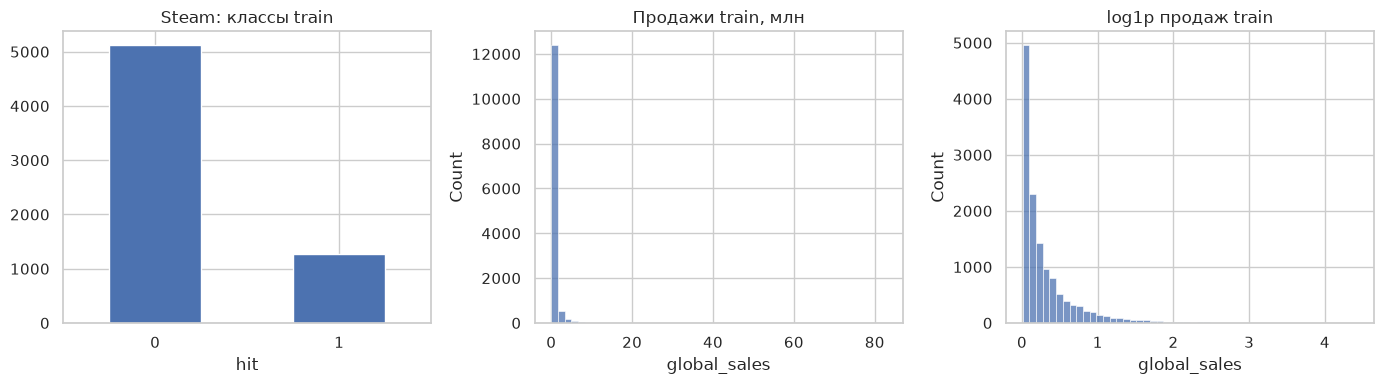

,Категорий в train
platform,30
genre,12
publisher,533


In [5]:
class Features(TransformerMixin, BaseEstimator):
    def __init__(self, task="c"):
        self.task = task
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        out = X.copy()
        if self.task == "c":
            out["wishlist_per_team"] = out.wishlists_k / (out.team_size + 1)
            out["wishlist_trailer_ratio"] = out.wishlists_k / (out.trailer_views_k + 1)
            out["wishlist_price"] = out.wishlists_k * out.price_usd
        else:
            out["platform_genre"] = out.platform.fillna("unknown") + " / " + out.genre.fillna("unknown")
            out["decade"] = ((out.year // 10) * 10).astype("Int64").astype("string").fillna("unknown").astype(object)
        return out

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
yc_train.value_counts().sort_index().plot.bar(ax=axes[0], rot=0, title="Steam: классы train")
sns.histplot(yr_train, bins=50, ax=axes[1]); axes[1].set_title("Продажи train, млн")
sns.histplot(np.log1p(yr_train), bins=50, ax=axes[2]); axes[2].set_title("log1p продаж train")
plt.tight_layout(); plt.show()
display(Xr_train[sales_cat].nunique().rename("Категорий в train").to_frame())

### 3b–3c. Проверка гипотез и выбор по CV
Сначала сравниваем H0 и H1 при одинаковых параметрах. Для H2 выбираем лучшую из этих двух подготовок по CV, затем проверяем явно заданную небольшую сетку. Это последовательное исследование, а не исчерпывающий поиск всех комбинаций. H3 использует ту же подготовку и сетку, меняется только цель. H4 увеличивает число деревьев лучшего кандидата этапов H0–H3.

Все оценки получены на одинаковых fold внутри задачи. `score` — AP или **−MAE**, поэтому больше — лучше; `std` — разброс fold, не доверительный интервал. В финальном выборе участвуют все кандидаты, включая H0. OOB внутри поиска отключаем для экономии времени, в финальных моделях включаем. При повторном выборе на одних CV-разбиениях оценки могут быть оптимистичны; независимый тест остаётся отдельной оценкой.

In [6]:
candidates, experiments, searches = {"c": {}, "r": {}}, [], {}
for task, X, y, folds, scoring in [("c", Xc_train, yc_train, cv_c, "average_precision"),
                                  ("r", Xr_train, yr_train, cv_r, "neg_mean_absolute_error")]:
    preparation_scores = {}
    for name, engineered in [("H0 baseline", False), ("H1 features", True)]:
        model = pipeline(task, estimator(task), engineered)
        model.set_params(model__oob_score=False)
        scores = cross_val_score(model, X, y, cv=folds, scoring=scoring, n_jobs=1)
        candidates[task][name] = model
        preparation_scores[engineered] = scores.mean()
        experiments.append({"task": task, "experiment": name, "score": scores.mean(), "std": scores.std()})
    engineered = preparation_scores[True] > preparation_scores[False]
    print(task, "Подготовка для дальнейших гипотез:", "расширенная" if engineered else "исходная")
    grid = [{"model__max_depth": [8, None], "model__min_samples_leaf": [5, 25], "model__max_features": ["sqrt"]},
            {"model__max_depth": [None], "model__min_samples_leaf": [25], "model__max_features": [0.5]}]
    if task == "c":
        for item in grid: item["model__class_weight"] = [None, "balanced"]
    model = pipeline(task, estimator(task), engineered)
    model.set_params(model__oob_score=False)
    variants = [("H2 tuned forest", model, grid)]
    if task == "r":
        variants.append(("H3 tuned log target", TransformedTargetRegressor(regressor=clone(model), func=np.log1p, inverse_func=np.expm1),
                         [{"regressor__"+k: v for k, v in item.items()} for item in grid]))
    for name, model, params in variants:
        search = GridSearchCV(model, params, cv=folds, scoring=scoring, n_jobs=1, refit=True, error_score="raise")
        search.fit(X, y)
        searches[(task, name)] = search
        candidates[task][name] = search.best_estimator_
        experiments.append({"task": task, "experiment": name, "score": search.best_score_,
                            "std": search.cv_results_["std_test_score"][search.best_index_]})
        print(task, name, search.best_params_)
        display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score"))
    previous = max([row for row in experiments if row["task"] == task], key=lambda row: row["score"])
    larger = clone(candidates[task][previous["experiment"]])
    prefix = "regressor__model__" if isinstance(larger, TransformedTargetRegressor) else "model__"
    larger.set_params(**{prefix + "n_estimators": 64})
    scores = cross_val_score(larger, X, y, cv=folds, scoring=scoring, n_jobs=1)
    name = "H4 64 trees from " + previous["experiment"]
    candidates[task][name] = larger
    experiments.append({"task": task, "experiment": name, "score": scores.mean(), "std": scores.std()})
    print(task, "H4 минус лучший предыдущий этап:", scores.mean() - previous["score"])
cv_table = pd.DataFrame(experiments)
display(cv_table)
cv_table.to_csv(RESULTS / "cv_experiments.csv", index=False)
for task in ["c", "r"]:
    tab = cv_table[cv_table.task == task].set_index("experiment")
    for name, reference in [("H1 features", "H0 baseline"),
                            ("H2 tuned forest", tab.loc[["H0 baseline", "H1 features"], "score"].idxmax())]:
        gain = tab.loc[name, "score"] - tab.loc[reference, "score"]
        print(task, name, "минус", reference, round(gain, 5), "— поддержана по среднему CV" if gain > 0 else "— не поддержана")
    if task == "r":
        print("r H3 минус H2:", tab.loc["H3 tuned log target", "score"] - tab.loc["H2 tuned forest", "score"])

c Подготовка для дальнейших гипотез: расширенная


c H2 tuned forest {'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 25}


,params,mean_test_score,std_test_score,rank_test_score
5,"{'model__class_weight': 'balanced', 'model__ma...",0.679943,0.029437,1
7,"{'model__class_weight': 'balanced', 'model__ma...",0.678622,0.028808,2
1,"{'model__class_weight': None, 'model__max_dept...",0.677845,0.023657,3
3,"{'model__class_weight': None, 'model__max_dept...",0.676555,0.026330,4
8,"{'model__class_weight': None, 'model__max_dept...",0.676224,0.024855,5
0,"{'model__class_weight': None, 'model__max_dept...",0.675659,0.023628,6
4,"{'model__class_weight': 'balanced', 'model__ma...",0.674465,0.031532,7
9,"{'model__class_weight': 'balanced', 'model__ma...",0.674384,0.023698,8
2,"{'model__class_weight': None, 'model__max_dept...",0.669052,0.028358,9
6,"{'model__class_weight': 'balanced', 'model__ma...",0.663620,0.031272,10


c H4 минус лучший предыдущий этап: 0.0002209186281775244


r Подготовка для дальнейших гипотез: исходная


r H2 tuned forest {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 25}


... (2 outputs left out)

,params,mean_test_score,std_test_score,rank_test_score
4,"{'regressor__model__max_depth': None, 'regress...",-0.447091,0.014504,1
2,"{'regressor__model__max_depth': None, 'regress...",-0.457447,0.016092,2
3,"{'regressor__model__max_depth': None, 'regress...",-0.482491,0.016534,3
0,"{'regressor__model__max_depth': 8, 'regressor_...",-0.484496,0.017209,4
1,"{'regressor__model__max_depth': 8, 'regressor_...",-0.489728,0.016321,5


r H4 минус лучший предыдущий этап: 0.0007296929302471056


,task,experiment,score,std
0,c,H0 baseline,0.644000,0.023645
1,c,H1 features,0.646964,0.027955
2,c,H2 tuned forest,0.679943,0.029437
3,c,H4 64 trees from H2 tuned forest,0.680164,0.026910
4,r,H0 baseline,-0.535489,0.005766
5,r,H1 features,-0.536379,0.005634
6,r,H2 tuned forest,-0.508396,0.006596
7,r,H3 tuned log target,-0.447091,0.014504
8,r,H4 64 trees from H3 tuned log target,-0.446361,0.014933


c H1 features минус H0 baseline 0.00296 — поддержана по среднему CV
c H2 tuned forest минус H1 features 0.03298 — поддержана по среднему CV
r H1 features минус H0 baseline -0.00089 — не поддержана
r H2 tuned forest минус H0 baseline 0.02709 — поддержана по среднему CV
r H3 минус H2: 0.06130467112839899


### 3d–3g. Обучение выбранных лесов и сравнение с пунктом 2
Фиксируем победителя по CV, включаем OOB и обучаем на всём train. Положительный выигрыш означает рост AP или снижение MAE. После оценки на тесте настройки не меняем.

In [7]:
selected, improved = {}, {}
for task, X, y, metric in [("c", Xc_train, yc_train, "AP"), ("r", Xr_train, yr_train, "MAE")]:
    ranking = cv_table[cv_table.task == task].sort_values("score", ascending=False, kind="stable")
    selected[task] = ranking.iloc[0].experiment
    model = clone(candidates[task][selected[task]])
    prefix = "regressor__model__" if isinstance(model, TransformedTargetRegressor) else "model__"
    model.set_params(**{prefix + "oob_score": True})
    improved[task] = model.fit(X, y)
    print(task, "Выбрано:", selected[task])
    display(evaluate("sklearn improved", task, improved[task]))
    table = pd.DataFrame(rows).query("task == @task").set_index("model")
    a, b = table.loc["sklearn baseline", metric], table.loc["sklearn improved", metric]
    gain = b-a if task == "c" else a-b
    display(Markdown(f"**Вывод пункта 3 ({task}):** {metric}: {a:.5f} → {b:.5f}, выигрыш {gain:+.5f}. "
                     + ("Улучшение подтвердилось на тесте." if gain > 0 else "Улучшение на тесте не подтверждено.")))

c Выбрано: H4 64 trees from H2 tuned forest


/home/skelet0no/PycharmProjects/knn-classification-regression/.venv/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,sklearn improved,0.717591,0.901565,0.632065,0.500914,0.85625,0.821484,0.800625,0.052298


**Вывод пункта 3 (c):** AP: 0.67225 → 0.71759, выигрыш +0.04535. Улучшение подтвердилось на тесте.

r Выбрано: H4 64 trees from H3 tuned log target


,task,model,MAE,RMSE,R2,predict_seconds
0,r,sklearn improved,0.43827,1.49565,0.100243,0.091396


**Вывод пункта 3 (r):** MAE: 0.49702 → 0.43827, выигрыш +0.05875. Улучшение подтвердилось на тесте.

## 4. Собственная имплементация
### 4a. CART со случайными признаками
Расширяем алгоритм третьей работы. Для каждого узла случайно выбираем до `max_features` непостоянных признаков, затем ищем лучший порог по Gini или взвешенной дисперсии. Если выбранные признаки не дают допустимого разделения с учётом размера листа, последовательно проверяем остальные до первого допустимого варианта. Пороги проверяем между различными значениями, используем кумулятивные суммы; разбиение с нулевым выигрышем допускается, например для XOR.

Входные признаки приводим к float32, суммы считаем в float64. Дерево принимает веса строк: число повторений в bootstrap передаётся как вес, а ограничения размера листа считаются по **уникальным строкам bootstrap**, как при обучении sklearn с весами повторений. Прогноз в листе — взвешенные доли классов или взвешенное среднее.

Поиск случайных признаков, порогов и агрегирование реализованы на NumPy. Готовые деревья или леса sklearn внутри собственных моделей не вызываются. Случайные последовательности и разрешение ничьих отличаются от sklearn, поэтому полное совпадение лесов не предполагается. Проверяем свойства алгоритма и контролируемые случаи, а затем сравниваем фактическое качество.

Узлы строятся через стек заданий с обходом в глубину. Это сохраняет порядок генерации случайных признаков, но не удерживает большие временные матрицы родительских узлов в рекурсивном стеке.

In [8]:
def feature_count(value, n):
    if value is None:
        return n
    if isinstance(value, str):
        if value == "sqrt": return max(1, int(np.sqrt(n)))
        if value == "log2": return max(1, int(np.log2(n)))
    elif isinstance(value, (int, np.integer)) and not isinstance(value, bool):
        if 1 <= value <= n: return int(value)
    elif isinstance(value, (float, np.floating)) and 0 < value <= 1:
        return max(1, int(value*n))
    raise ValueError("Некорректный max_features")

class NumpyCART(BaseEstimator):
    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1, class_weight=None, max_features=None, random_state=42):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.class_weight = class_weight
        self.max_features = max_features
        self.random_state = random_state
    def fit(self, X, y, sample_weight=None):
        X, y = check_X_y(X, y, dtype=np.float32)
        if self.max_depth is not None and (not isinstance(self.max_depth, (int, np.integer)) or self.max_depth < 1):
            raise ValueError("max_depth: None или положительное целое")
        for name, value, minimum in [("min_samples_split", self.min_samples_split, 2), ("min_samples_leaf", self.min_samples_leaf, 1)]:
            if not isinstance(value, (int, np.integer)) or value < minimum:
                raise ValueError(name + ": некорректное значение")
        if self.class_weight not in (None, "balanced") or (not self._classification and self.class_weight is not None):
            raise ValueError("class_weight поддерживается только для классификации: None или balanced")
        self.n_features_in_ = X.shape[1]
        self.max_features_ = feature_count(self.max_features, X.shape[1])
        self._rng = np.random.default_rng(self.random_state)
        self._X = X
        if self._classification:
            self.classes_, encoded = np.unique(y, return_inverse=True)
            self._y = encoded
            self._weights = np.ones(len(y)) if self.class_weight is None else len(y) / (len(self.classes_) * np.bincount(encoded)[encoded])
        else:
            self._y = np.asarray(y, dtype=float)
            self._weights = np.ones(len(y))
        if sample_weight is not None:
            sample_weight = np.asarray(sample_weight, dtype=float)
            if sample_weight.shape != (len(y),) or not np.isfinite(sample_weight).all() or (sample_weight <= 0).any():
                raise ValueError("sample_weight должны быть конечными и положительными")
            self._weights *= sample_weight
        self.nodes_ = []
        pending = [(np.arange(len(y)), 0, None, None)]
        while pending:
            ids, depth, parent, side = pending.pop()
            index, children = self._grow(ids, depth)
            if parent is not None:
                self.nodes_[parent][side] = index
            if children is not None:
                left_ids, right_ids = children
                pending.append((right_ids, depth+1, index, "right"))
                pending.append((left_ids, depth+1, index, "left"))
        self.depth_ = max(node["depth"] for node in self.nodes_)
        self.n_leaves_ = sum(node["feature"] < 0 for node in self.nodes_)
        del self._X, self._y, self._weights
        return self
    def _grow(self, ids, depth):
        X, y, weights = self._X[ids], self._y[ids], self._weights[ids]
        n, total = len(ids), weights.sum()
        if self._classification:
            signal = np.eye(len(self.classes_))[y] * weights[:, None]
            totals = signal.sum(axis=0)
            value = totals / total
            impurity = max(0., 1 - np.sum(value**2))
        else:
            value = np.average(y, weights=weights)
            centered = y - value
            signal = (centered * weights)[:, None]
            totals = signal.sum(axis=0)
            impurity = np.average(centered**2, weights=weights)
        index = len(self.nodes_)
        node = {"value": value, "feature": -1, "depth": depth, "n_samples": n,
                "impurity": float(impurity), "gain": 0.}
        self.nodes_.append(node)
        if impurity <= 1e-14 or n < max(self.min_samples_split, 2 * self.min_samples_leaf) or (self.max_depth is not None and depth >= self.max_depth):
            return index, None
        parent_score = np.sum(totals**2) / total
        best_gain, best = -np.inf, None
        features = self._rng.permutation(np.flatnonzero(np.ptp(X, axis=0) > 1e-7))
        for inspected, feature in enumerate(features):
            if inspected >= self.max_features_ and best is not None:
                break
            values = X[:, feature]
            low, high = values.min(), values.max()
            if np.all((values == low) | (values == high)):
                left = values == low
                count = int(left.sum())
                if count < self.min_samples_leaf or n - count < self.min_samples_leaf:
                    continue
                left_w = np.array([weights[left].sum()])
                left_s = signal[left].sum(axis=0, keepdims=True)
                positions = np.array([count - 1])
                order = None
                thresholds = np.array([float(low)/2 + float(high)/2])
            else:
                order = np.argsort(values, kind="stable")
                sorted_values = values[order]
                positions = np.flatnonzero(np.diff(sorted_values) > 1e-7)
                positions = positions[(positions + 1 >= self.min_samples_leaf) & (n - positions - 1 >= self.min_samples_leaf)]
                if not len(positions):
                    continue
                left_w = np.cumsum(weights[order], dtype=float)[positions]
                left_s = np.cumsum(signal[order], axis=0, dtype=float)[positions]
                thresholds = sorted_values[positions].astype(float)/2 + sorted_values[positions+1].astype(float)/2
            right_w = total - left_w
            scores = (left_s**2).sum(axis=1)/left_w + ((totals-left_s)**2).sum(axis=1)/right_w
            gains = (scores - parent_score) / total
            pos = int(np.argmax(gains))
            gain = float(gains[pos])
            if gain > best_gain + 1e-12:
                best_gain = gain
                best = (int(feature), float(thresholds[pos]))
        if best is None or best_gain < -1e-12:
            return index, None
        feature, threshold = best
        left = X[:, feature] <= threshold
        node.update(feature=feature, threshold=threshold, gain=max(0., best_gain))
        return index, (ids[left], ids[~left])
    def _values(self, X):
        check_is_fitted(self, "nodes_")
        X = check_array(X, dtype=np.float32)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от train")
        leaves = np.zeros(len(X), dtype=int)
        stack = [(0, np.arange(len(X)))]
        while stack:
            index, ids = stack.pop()
            node = self.nodes_[index]
            if node["feature"] < 0:
                leaves[ids] = index
            else:
                left = X[ids, node["feature"]] <= node["threshold"]
                if left.any(): stack.append((node["left"], ids[left]))
                if (~left).any(): stack.append((node["right"], ids[~left]))
        return np.asarray([self.nodes_[index]["value"] for index in leaves])
    def get_depth(self):
        check_is_fitted(self, "nodes_")
        return self.depth_
    def get_n_leaves(self):
        check_is_fitted(self, "nodes_")
        return self.n_leaves_

class NumpyDecisionTreeClassifier(ClassifierMixin, NumpyCART):
    _classification = True
    def predict_proba(self, X):
        return self._values(X)
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

class NumpyDecisionTreeRegressor(RegressorMixin, NumpyCART):
    _classification = False
    def predict(self, X):
        return self._values(X)

### 4a. Bootstrap, усреднение и OOB
Для каждого дерева независимо генерируем seed и n индексов с возвращением. Без весов классов выбор равновероятный. Для `class_weight="balanced"` вычисляем веса n/(K·n_class) по всему train и выбираем строки с вероятностями, пропорциональными этим весам; затем обучаем дерево с весами bootstrap-кратностей, без повторного умножения на веса классов. Это соответствует реализации в проверенном окружении sklearn 1.9.1 (`sklearn.ensemble._forest._generate_sample_indices` и `_parallel_build_trees`, проверены в установленном исходном коде). Поведение весов зависит от версии sklearn; воспроизводимость сравнения относится к выведенной в начале версии. Без bootstrap веса классов применяются непосредственно при обучении дерева. balanced_subsample не реализован.

В классификации усредняем **вероятности**, не метки. Если bootstrap пропустил редкий класс, выравниваем столбцы вероятностей по глобальному списку классов. В регрессии усредняем числовые прогнозы. OOB для строки — среднее только тех деревьев, где строка отсутствовала в bootstrap. Если таких деревьев нет, оставляем NaN и исключаем строку из OOB-метрики, показывая покрытие.

При равновероятном bootstrap около 36.8% строк остаются вне одной выборки размера n; это ориентир для больших n, а не точная доля. При balanced вероятность отсутствия строки i равна (1−pᵢ)ⁿ и различается между классами; ориентир 36.8% к такому случаю напрямую не применяется. Увеличение числа деревьев обычно повышает покрытие OOB. sklearn может выдать предупреждение о неполном покрытии: такие строки исключаются из итоговой OOB-метрики, а покрытие выводится явно. Препроцессинг обучен на всём train, поэтому OOB здесь оценивает лес при фиксированном преобразовании и не заменяет CV всего Pipeline. Для группированных продаж OOB также не исключает попадания разных платформ одной игры в разные bootstrap-части: основная оценка остаётся групповой CV и тестом.

Полное построение леса примерно в T раз дороже одного дерева, память растёт с суммарным числом узлов; предсказание проходит T деревьев. Не реализуем warm_start, pruning, параллелизм и произвольные веса классов; эти возможности не используются в исследовании.

In [9]:
class NumpyForest(BaseEstimator):
    def __init__(self, n_estimators=32, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 max_features="sqrt", class_weight=None, bootstrap=True, oob_score=True, random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.class_weight = class_weight
        self.bootstrap = bootstrap
        self.oob_score = oob_score
        self.random_state = random_state
    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=np.float32)
        if not isinstance(self.n_estimators, (int, np.integer)) or self.n_estimators < 1:
            raise ValueError("n_estimators должно быть положительным целым")
        if self.oob_score and not self.bootstrap:
            raise ValueError("OOB требует bootstrap=True")
        if self.class_weight not in (None, "balanced") or (not self._classification and self.class_weight is not None):
            raise ValueError("Некорректный class_weight")
        feature_count(self.max_features, X.shape[1])
        self.n_features_in_ = X.shape[1]
        n = len(y)
        if self._classification:
            self.classes_, target = np.unique(y, return_inverse=True)
            class_weights = np.ones(len(self.classes_)) if self.class_weight is None else n/(len(self.classes_)*np.bincount(target))
            global_weights = class_weights[target]
            oob_sum = np.zeros((n, len(self.classes_)))
        else:
            target = np.asarray(y, dtype=float)
            global_weights = np.ones(n)
            oob_sum = np.zeros(n)
        self.estimators_, self.estimators_samples_ = [], []
        self.oob_counts_ = np.zeros(n, dtype=int)
        rng = np.random.default_rng(self.random_state)
        for _ in range(self.n_estimators):
            tree_seed = int(rng.integers(0, 2**31-1))
            if self.bootstrap:
                if self.class_weight == "balanced":
                    indices = rng.choice(n, size=n, replace=True, p=global_weights/global_weights.sum())
                else:
                    indices = rng.integers(0, n, size=n)
            else:
                indices = np.arange(n)
            counts = np.bincount(indices, minlength=n)
            used = np.flatnonzero(counts)
            cls = NumpyDecisionTreeClassifier if self._classification else NumpyDecisionTreeRegressor
            tree = cls(max_depth=self.max_depth, min_samples_split=self.min_samples_split,
                       min_samples_leaf=self.min_samples_leaf, max_features=self.max_features, random_state=tree_seed)
            fit_weights = counts[used] if self.bootstrap else global_weights[used]
            tree.fit(X[used], target[used], sample_weight=fit_weights)
            self.estimators_.append(tree)
            self.estimators_samples_.append(indices)
            if self.oob_score:
                held_out = np.flatnonzero(counts == 0)
                if len(held_out):
                    if self._classification:
                        aligned = np.zeros((len(held_out), len(self.classes_)))
                        aligned[:, tree.classes_.astype(int)] = tree.predict_proba(X[held_out])
                        oob_sum[held_out] += aligned
                    else:
                        oob_sum[held_out] += tree.predict(X[held_out])
                    self.oob_counts_[held_out] += 1
        if self.oob_score:
            valid = self.oob_counts_ > 0
            if self._classification:
                self.oob_decision_function_ = np.full_like(oob_sum, np.nan)
                self.oob_decision_function_[valid] = oob_sum[valid]/self.oob_counts_[valid, None]
            else:
                self.oob_prediction_ = np.full(n, np.nan)
                self.oob_prediction_[valid] = oob_sum[valid]/self.oob_counts_[valid]
        return self
    def _check(self, X):
        check_is_fitted(self, "estimators_")
        X = check_array(X, dtype=np.float32)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от train")
        return X

class NumpyRandomForestClassifier(ClassifierMixin, NumpyForest):
    _classification = True
    def predict_proba(self, X):
        X = self._check(X)
        total = np.zeros((len(X), len(self.classes_)))
        for tree in self.estimators_:
            total[:, tree.classes_.astype(int)] += tree.predict_proba(X)
        return total/len(self.estimators_)
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

class NumpyRandomForestRegressor(RegressorMixin, NumpyForest):
    _classification = False
    def predict(self, X):
        X = self._check(X)
        return sum(tree.predict(X) for tree in self.estimators_)/len(self.estimators_)

### Проверки собственного алгоритма
Проверяем критерии CART на однозначном пороге; лес без bootstrap и с одним признаком — против sklearn; воспроизводимость seed и bootstrap; усреднение вероятностей; выравнивание редкого класса; ручной пересчёт OOB одной строки; ограничения глубины и листа; отклонение недопустимых настроек. Отсутствующие OOB-прогнозы не подменяются нулём. Независимые случайные леса со sklearn не обязаны совпадать дерево в дерево.

In [10]:
x = np.array([[0.], [1.], [2.], [4.], [5.], [6.]])
for task, y in [("c", np.array([0, 0, 0, 1, 1, 1])), ("r", np.array([1., 1., 1., 8., 8., 8.]))]:
    cls = NumpyRandomForestClassifier if task == "c" else NumpyRandomForestRegressor
    ref_cls = RandomForestClassifier if task == "c" else RandomForestRegressor
    params = dict(n_estimators=3, max_depth=1, max_features=1., bootstrap=False, oob_score=False, random_state=SEED)
    own = cls(**params).fit(x, y)
    ref = ref_cls(**params).fit(x, y)
    np.testing.assert_allclose(own.predict(x), ref.predict(x))
    assert all(tree.nodes_[0]["threshold"] == 3. for tree in own.estimators_)
    a = cls(n_estimators=12, max_depth=2, min_samples_leaf=2, random_state=SEED).fit(x, y)
    b = clone(a).fit(x, y)
    np.testing.assert_allclose(a.predict(x), b.predict(x))
    for ia, ib in zip(a.estimators_samples_, b.estimators_samples_): np.testing.assert_array_equal(ia, ib)
    assert any(len(np.unique(indices)) < len(x) for indices in a.estimators_samples_)
    assert all(tree.get_depth() <= 2 for tree in a.estimators_)
    assert all(node["n_samples"] >= 2 for tree in a.estimators_ for node in tree.nodes_ if node["feature"] < 0)
    index = int(np.flatnonzero(a.oob_counts_ > 0)[0])
    contributors = [tree for tree, indices in zip(a.estimators_, a.estimators_samples_) if index not in indices]
    if task == "c":
        manual = np.zeros(2)
        for tree in contributors: manual[tree.classes_.astype(int)] += tree.predict_proba(x[[index]])[0]
        np.testing.assert_allclose(manual/len(contributors), a.oob_decision_function_[index])
        np.testing.assert_allclose(a.predict_proba(x).sum(axis=1), 1.)
    else:
        np.testing.assert_allclose(np.mean([tree.predict(x[[index]])[0] for tree in contributors]), a.oob_prediction_[index])
rare = NumpyRandomForestClassifier(n_estimators=20, random_state=SEED).fit(np.arange(20).reshape(-1, 1), [0]*19+[1])
assert any(len(tree.classes_) == 1 for tree in rare.estimators_)
np.testing.assert_allclose(rare.predict_proba([[0], [19]]).sum(axis=1), 1.)
for params in [dict(n_estimators=0), dict(bootstrap=False, oob_score=True), dict(max_features=0)]:
    try:
        NumpyRandomForestRegressor(**params).fit(x, np.arange(6))
    except ValueError:
        pass
    else:
        raise AssertionError("Некорректные параметры не отклонены")
print("Проверки CART, bootstrap, усреднения, воспроизводимости и OOB пройдены.")
balanced = NumpyRandomForestClassifier(n_estimators=20, class_weight="balanced", random_state=SEED).fit(np.arange(20).reshape(-1, 1), [0]*19+[1])
positive_share = np.mean([np.mean(indices == 19) for indices in balanced.estimators_samples_])
assert .35 < positive_share < .65
print("Проверка взвешенного bootstrap при balanced пройдена.")

Проверки CART, bootstrap, усреднения, воспроизводимости и OOB пройдены.
Проверка взвешенного bootstrap при balanced пройдена.


### 4b–4e. Собственные леса с исходным бейзлайном
Сохраняем подготовку, критерии, число деревьев, ограничения и распределение случайных подвыборок. Заменяем только estimator. Seed фиксирован у обеих библиотек, но генераторы и последовательности случайных действий различны, поэтому одинаковые значения seed не означают одинаковые bootstrap-выборки или разбиения.

In [11]:
def replace_model(model, task):
    result = clone(model)
    if isinstance(result, TransformedTargetRegressor):
        result.regressor = replace_model(result.regressor, task)
    else:
        ref = result.named_steps["model"]
        cls = NumpyRandomForestClassifier if task == "c" else NumpyRandomForestRegressor
        names = ["n_estimators", "max_depth", "min_samples_split", "min_samples_leaf", "max_features", "bootstrap", "oob_score", "random_state"]
        params = {name: ref.get_params()[name] for name in names}
        if task == "c": params["class_weight"] = ref.class_weight
        result.set_params(model=cls(**params))
    return result
own_base_c = replace_model(base_c, "c").fit(Xc_train, yc_train)
own_base_r = replace_model(base_r, "r").fit(Xr_train, yr_train)
display(evaluate("numpy baseline", "c", own_base_c))
display(evaluate("numpy baseline", "r", own_base_r))
for task, metric in [("c", "AP"), ("r", "MAE")]:
    tab = pd.DataFrame(rows).query("task == @task").set_index("model")
    delta = tab.loc["numpy baseline", metric] - tab.loc["sklearn baseline", metric]
    display(Markdown(f"**Вывод 4e ({task}):** NumPy baseline минус sklearn baseline по {metric}: {delta:+.6f}. "
                     "Это независимые реализации случайного алгоритма; сравнение качества дополняет, но не заменяет проверки корректности."))

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,numpy baseline,0.657658,0.869846,0.582878,0.69869,0.5,0.723047,0.856875,0.318576


,task,model,MAE,RMSE,R2,predict_seconds
0,r,numpy baseline,0.474581,1.423833,0.184576,1.842198


**Вывод 4e (c):** NumPy baseline минус sklearn baseline по AP: -0.014588. Это независимые реализации случайного алгоритма; сравнение качества дополняет, но не заменяет проверки корректности.

**Вывод 4e (r):** NumPy baseline минус sklearn baseline по MAE: -0.022438. Это независимые реализации случайного алгоритма; сравнение качества дополняет, но не заменяет проверки корректности.

### 4f–4j. Перенос улучшений, итоговые метрики и OOB
Переносим выбранную по CV подготовку, параметры, веса классов и преобразование цели, затем обучаем собственные леса на train. Повторного поиска по тесту нет. OOB-метрики приводим в тех же единицах, что и тест: у модели с log1p цели выполняем expm1 после усреднения OOB-прогнозов в логарифмической шкале. OOB-строки без прогнозов исключаем и показываем покрытие; прогнозы OOB не используются для подбора.

Для sklearn восстанавливаем число OOB-деревьев через bootstrap-индексы, поскольку библиотека может заполнять отсутствующие OOB-прогнозы нулями. Сводные глубины и число деревьев помогают оценить сложность и стоимость моделей.

In [12]:
own_improved = {}
for task, X, y in [("c", Xc_train, yc_train), ("r", Xr_train, yr_train)]:
    own_improved[task] = replace_model(improved[task], task).fit(X, y)
    display(evaluate("numpy improved", task, own_improved[task]))
metrics = pd.DataFrame(rows)
display(metrics[metrics.task == "c"].dropna(axis=1, how="all"))
display(metrics[metrics.task == "r"].dropna(axis=1, how="all"))
metrics.to_csv(RESULTS / "test_metrics.csv", index=False)
oob_rows = []
for task, y in [("c", yc_train), ("r", yr_train)]:
    models = [("sklearn baseline", base_c if task == "c" else base_r),
              ("numpy baseline", own_base_c if task == "c" else own_base_r),
              ("sklearn improved", improved[task]), ("numpy improved", own_improved[task])]
    for name, model in models:
        pipe = model.regressor_ if isinstance(model, TransformedTargetRegressor) else model
        forest = pipe.named_steps["model"]
        counts = np.zeros(len(y), dtype=int)
        for indices in forest.estimators_samples_: counts += np.bincount(indices, minlength=len(y)) == 0
        valid = counts > 0
        if task == "c":
            pred = forest.oob_decision_function_[valid, 1]
            value = average_precision_score(y.to_numpy()[valid], pred)
        else:
            pred = forest.oob_prediction_[valid]
            if isinstance(model, TransformedTargetRegressor): pred = model.transformer_.inverse_transform(pred.reshape(-1, 1)).ravel()
            value = mean_absolute_error(y.to_numpy()[valid], pred)
        oob_rows.append({"task": task, "model": name, "OOB coverage": valid.mean(),
            "OOB AP" if task == "c" else "OOB MAE": value, "trees": len(forest.estimators_),
            "mean depth": np.mean([tree.get_depth() for tree in forest.estimators_])})
display(pd.DataFrame(oob_rows))

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,numpy improved,0.729041,0.901826,0.626728,0.49635,0.85,0.817187,0.7975,0.209597


,task,model,MAE,RMSE,R2,predict_seconds
0,r,numpy improved,0.437276,1.494611,0.101492,0.415503


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,Dummy,0.200000,0.500000,0.000000,0.000000,0.000000,0.500000,0.800000,0.028241
2,c,sklearn baseline,0.672246,0.882676,0.576147,0.697778,0.490625,0.718750,0.855625,0.048302
4,c,sklearn improved,0.717591,0.901565,0.632065,0.500914,0.856250,0.821484,0.800625,0.052298
6,c,numpy baseline,0.657658,0.869846,0.582878,0.698690,0.500000,0.723047,0.856875,0.318576
8,c,numpy improved,0.729041,0.901826,0.626728,0.496350,0.850000,0.817187,0.797500,0.209597


,task,model,predict_seconds,MAE,RMSE,R2
1,r,Dummy,0.003264,0.456185,1.616683,-0.051272
3,r,sklearn baseline,0.081421,0.497019,1.445628,0.159422
5,r,sklearn improved,0.091396,0.438270,1.495650,0.100243
7,r,numpy baseline,1.842198,0.474581,1.423833,0.184576
9,r,numpy improved,0.415503,0.437276,1.494611,0.101492


,task,model,OOB coverage,OOB AP,trees,mean depth,OOB MAE
0,c,sklearn baseline,1.000000,0.602230,32,25.281250,NaN
1,c,numpy baseline,1.000000,0.616071,32,23.500000,NaN
2,c,sklearn improved,0.998594,0.685929,64,8.000000,NaN
3,c,numpy improved,0.998906,0.682697,64,8.000000,NaN
4,r,sklearn baseline,1.000000,NaN,32,103.750000,0.535712
5,r,numpy baseline,1.000000,NaN,32,93.593750,0.513026
6,r,sklearn improved,1.000000,NaN,64,36.531250,0.442352
7,r,numpy improved,1.000000,NaN,64,38.671875,0.441625


### Графики качества и разнообразия деревьев
PR-кривые и матрица ошибок показывают ранжирование и фиксированный порог. Для продаж отображаем факт/прогноз и остатки. Распределение глубины описывает состав выбранных лесов; оно не является проверкой независимости деревьев. Важности sklearn по уменьшению нечистоты не являются причинными эффектами и могут смещаться в пользу признаков с большим числом порогов.

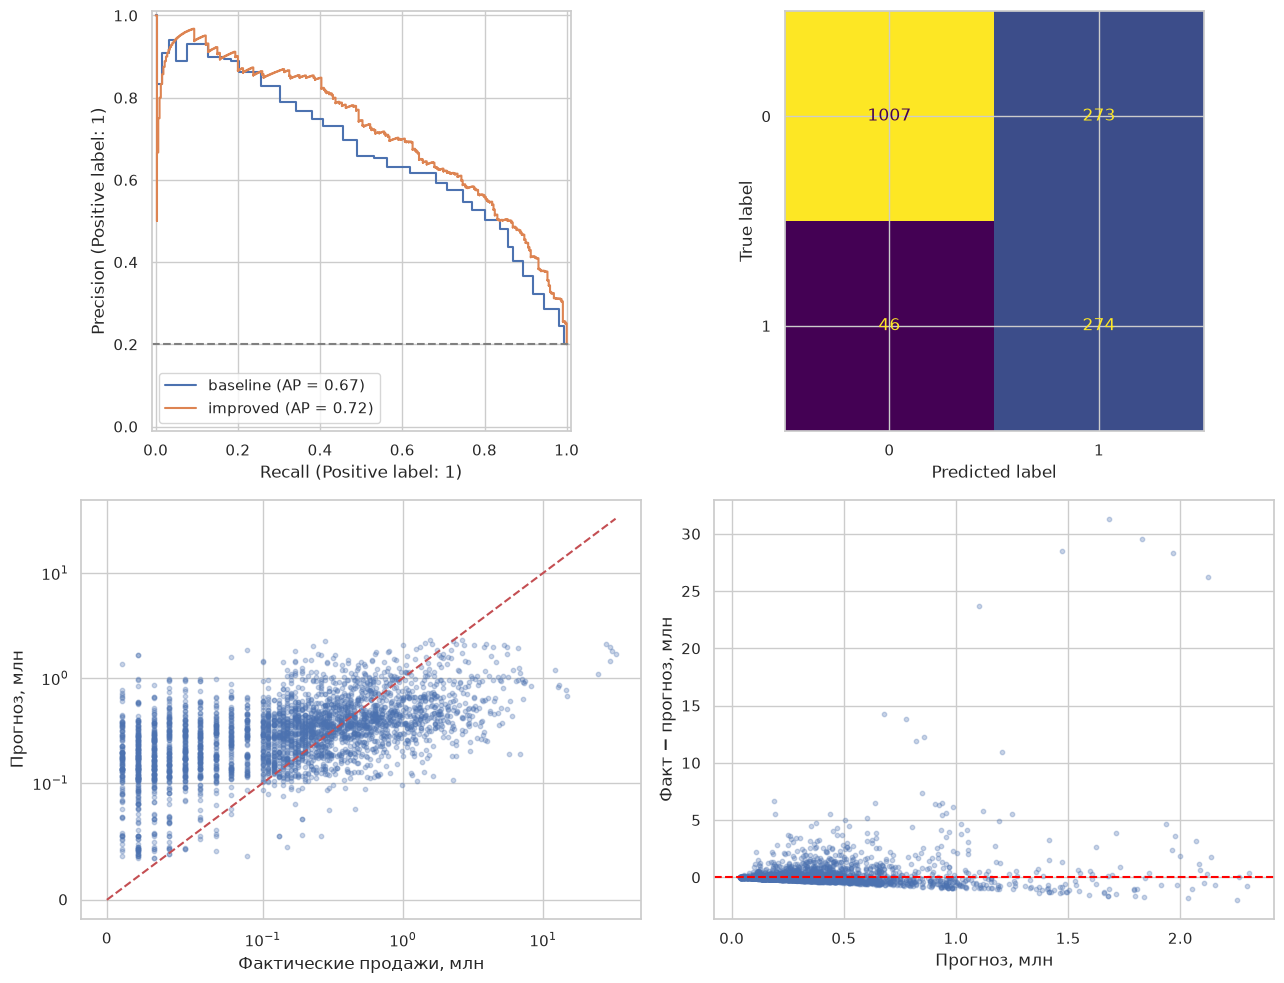

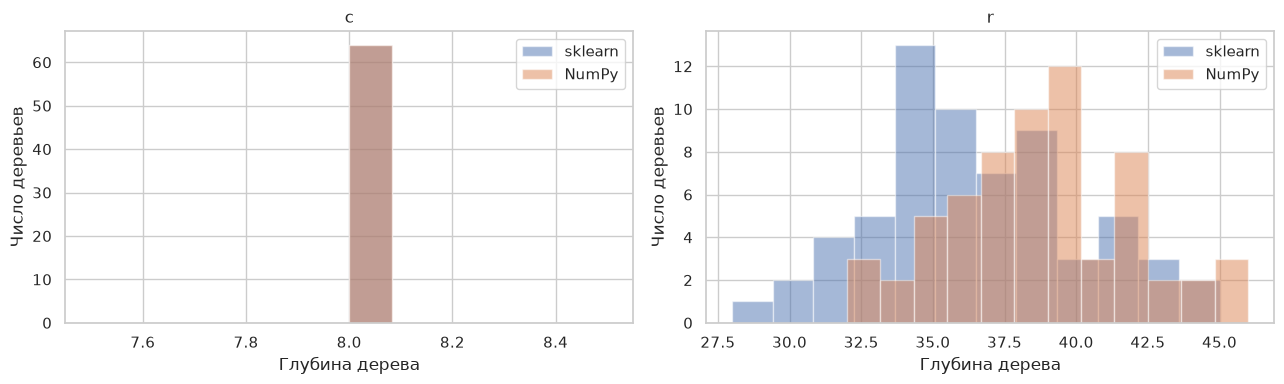

,Важность по снижению нечистоты
num__wishlists_k,0.343498
num__wishlist_price,0.232451
num__trailer_views_k,0.155829
num__wishlist_per_team,0.105269
num__team_size,0.037372
num__wishlist_trailer_ratio,0.025813
num__file_size_gb,0.021554
num__price_usd,0.019324
num__has_multiplayer,0.015629
num__is_indie,0.014487


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for stage in ["baseline", "improved"]:
    PrecisionRecallDisplay.from_predictions(yc_test, predictions[("c", "sklearn " + stage)][1], name=stage, ax=axes[0, 0])
axes[0, 0].axhline(yc_test.mean(), color="gray", linestyle="--")
ConfusionMatrixDisplay.from_predictions(yc_test, predictions[("c", "sklearn improved")][0], ax=axes[0, 1], colorbar=False)
pred = predictions[("r", "sklearn improved")]
axes[1, 0].scatter(yr_test, pred, alpha=.3, s=10)
axes[1, 0].plot([0, yr_test.max()], [0, yr_test.max()], "r--")
axes[1, 0].set_xscale("symlog", linthresh=.1); axes[1, 0].set_yscale("symlog", linthresh=.1)
axes[1, 0].set(xlabel="Фактические продажи, млн", ylabel="Прогноз, млн")
axes[1, 1].scatter(pred, yr_test.to_numpy()-pred, alpha=.3, s=10)
axes[1, 1].axhline(0, color="red", linestyle="--")
axes[1, 1].set(xlabel="Прогноз, млн", ylabel="Факт − прогноз, млн")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, task in zip(axes, ["c", "r"]):
    for name, model in [("sklearn", improved[task]), ("NumPy", own_improved[task])]:
        pipe = model.regressor_ if isinstance(model, TransformedTargetRegressor) else model
        depths = [tree.get_depth() for tree in pipe.named_steps["model"].estimators_]
        ax.hist(depths, bins=12, alpha=.5, label=name)
    ax.set(title=task, xlabel="Глубина дерева", ylabel="Число деревьев"); ax.legend()
plt.tight_layout(); plt.show()
model = improved["c"]
feature_names = model.named_steps["prep"].get_feature_names_out()
display(pd.Series(model.named_steps["model"].feature_importances_, index=feature_names,
                  name="Важность по снижению нечистоты").sort_values(ascending=False).head(12).to_frame())

### Выводы по пунктам 3g, 4e и 4j
Численные выводы ниже строятся по фактическим результатам. Отдельно оцениваем улучшение относительно исходного леса, отличие собственной реализации от sklearn и преимущество перед Dummy. Для независимых случайных лесов различия метрик ожидаемы; одинаковые seed не обеспечивают идентичные выборки и структуры.

Больше деревьев снижает случайный разброс усреднения, но не гарантирует рост качества и не устраняет смещение. Веса классов меняют вероятности и компромисс precision/recall; AP и F1 могут изменяться по-разному. Логарифм цели меняет обучающий критерий и центр усреднения; MAE и RMSE следует рассматривать совместно.

Один holdout не доказывает статистической значимости, а выбор на тех же CV-fold делает CV-оценки оптимистичными. OOB — дополнительная диагностика леса с фиксированным препроцессингом; для продаж она не заменяет групповые разбиения. Данные Steam синтетические, продажи исторические и отобраны по наличию продаж. Для реального внедрения нужны временная проверка, реальные дорелизные признаки и единый горизонт продаж.

In [14]:
for task, metric, label in [("c", "AP", "Классификация"), ("r", "MAE", "Регрессия")]:
    tab = metrics[metrics.task == task].set_index("model")
    a, b = tab.loc["sklearn baseline", metric], tab.loc["sklearn improved", metric]
    u, v = tab.loc["numpy baseline", metric], tab.loc["numpy improved", metric]
    gain = b-a if task == "c" else a-b
    own_gain = v-u if task == "c" else u-v
    dummy = tab.loc["Dummy", metric]
    beats_dummy = b > dummy if task == "c" else b < dummy
    display(Markdown(f"**{label}.** Выбрано по CV: `{selected[task]}`. "
        f"sklearn {metric}: {a:.5f} → {b:.5f} (выигрыш {gain:+.5f}); "
        f"NumPy: {u:.5f} → {v:.5f} (выигрыш {own_gain:+.5f}). "
        f"NumPy improved минус sklearn improved: {v-b:+.6f}. "
        f"Dummy: {dummy:.5f}. "
        + ("Улучшенная sklearn-модель превзошла Dummy." if beats_dummy else "Улучшенная sklearn-модель не превзошла Dummy по основной метрике.")
        + (" Перенос улучшений в NumPy дал выигрыш." if own_gain > 0 else " Перенос улучшений не дал выигрыша в NumPy на этом тесте.")))
r = metrics[metrics.task == "r"].set_index("model")
a, b = r.loc["sklearn baseline", "RMSE"], r.loc["sklearn improved", "RMSE"]
display(Markdown(f"**Компромисс регрессии:** RMSE {a:.5f} → {b:.5f} млн копий. "
    + ("Крупные ошибки уменьшились вместе с выбранным улучшением." if b < a else "Улучшение по основной метрике не означает уменьшения крупных ошибок.")))

**Классификация.** Выбрано по CV: `H4 64 trees from H2 tuned forest`. sklearn AP: 0.67225 → 0.71759 (выигрыш +0.04535); NumPy: 0.65766 → 0.72904 (выигрыш +0.07138). NumPy improved минус sklearn improved: +0.011450. Dummy: 0.20000. Улучшенная sklearn-модель превзошла Dummy. Перенос улучшений в NumPy дал выигрыш.

**Регрессия.** Выбрано по CV: `H4 64 trees from H3 tuned log target`. sklearn MAE: 0.49702 → 0.43827 (выигрыш +0.05875); NumPy: 0.47458 → 0.43728 (выигрыш +0.03731). NumPy improved минус sklearn improved: -0.000994. Dummy: 0.45618. Улучшенная sklearn-модель превзошла Dummy. Перенос улучшений в NumPy дал выигрыш.

**Компромисс регрессии:** RMSE 1.44563 → 1.49565 млн копий. Улучшение по основной метрике не означает уменьшения крупных ошибок.